In [1]:
%pip install scikit-fuzzy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from tensorflow.keras.models import Sequential  # type: ignore
from tensorflow.keras.layers import Dense, Dropout, Input  # type: ignore
from tensorflow.keras.optimizers import Adam  # type: ignore
from tensorflow.keras.callbacks import EarlyStopping  # type: ignore
from tensorflow.keras.backend import clear_session  # type: ignore
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score

# Przygotowanie danych

In [3]:
def read_currency_data(filepath: str, start_date: str):
    """
    reads file and cuts the unnecessary data: League and Confidence.
    Date is changed into day of the league, to transform date into number.
    returns DataFrame
    """
    df = pd.read_csv(filepath, sep=';', skipinitialspace=True)
    df['Date'] = pd.to_datetime(df['Date'])
    df = df[df['Pay'] == 'Chaos Orb']
    df['Day of league'] = (df['Date'] - pd.to_datetime(start_date)).dt.days + 1
    columns_to_drop = ['League', 'Date', 'Pay', 'Confidence']
    df = df.drop(columns=columns_to_drop)
    df = df.reset_index(drop=True)
    return df


def transform_currency_data(df):
    """
    Drop with all NaN
    Drop with 5 NaN's in Row - bad data
    Fill NaN's with data from day before, and fill first day's
    Cuts data to 100 days (Settlers is too large)
    returns DataFrame
    """
    df = df.pivot(index='Day of league', columns='Get', values='Value')
    df = df.dropna(axis=1, how='all')
    df = df.dropna(axis=1, thresh=len(df) - 4)
    df = df.ffill().bfill()
    df = df[df.index <= 100]
    return df.T


keepers_df = transform_currency_data(
    read_currency_data('data/Keepers.currency.csv', '2025-10-31'))
mercenaries_df = transform_currency_data(
    read_currency_data('data/Mercenaries.currency.csv', '2025-06-13'))
settlers_df = transform_currency_data(
    read_currency_data('data/Settlers.currency.csv', '2024-07-26'))
affiliction_df = transform_currency_data(
    read_currency_data('data/Affliction.currency.csv', '2023-12-08'))
necropolis_df = transform_currency_data(
    read_currency_data('data/Necropolis.currency.csv', '2024-03-29'))

In [4]:
ITEM = "Divine Orb"
WINDOW = 14
TEST_LIGA = -1
leagues = [necropolis_df, affiliction_df,
           settlers_df, mercenaries_df, keepers_df]
test_idx = TEST_LIGA % len(leagues)
contamination = 0.1
tscv = TimeSeriesSplit()

## Podział danych

In [5]:
def normalize(series):
    base = series.iloc[0]
    if base == 0 or pd.isna(base):
        return None
    return series / base


def make_windows(series, window):
    X, y = [], []
    for i in range(window, len(series)):
        X.append(series.iloc[i-window:i].values)
        y.append(series.iloc[i])
    return np.array(X), np.array(y)


X_train_list, y_train_list = [], []
for i, df in enumerate(leagues):
    if i == test_idx:
        continue
    if ITEM not in df.index:
        continue

    raw_series = df.loc[ITEM].dropna()

    norm = normalize(raw_series)
    if norm is None:
        continue

    X, y = make_windows(norm, WINDOW)

    X_train_list.append(X)
    y_train_list.append(y)

X_train = np.vstack(X_train_list)
y_train = np.concatenate(y_train_list)
print(f"Dane treningowe: {X_train.shape}")

print(X_train)

scaler_standard = StandardScaler()
X_train_standard = scaler_standard.fit_transform(X_train)

df_test = leagues[test_idx]
raw_test = df_test.loc[ITEM].dropna()
norm_test = normalize(raw_test)
base_price = raw_test.iloc[0]
initial_window = norm_test.iloc[:WINDOW].values

Dane treningowe: (344, 14)
[[1.         2.31578947 2.84210526 ... 4.57355263 4.39473684 4.07894737]
 [2.31578947 2.84210526 3.60526316 ... 4.39473684 4.07894737 4.02631579]
 [2.84210526 3.60526316 3.76315789 ... 4.07894737 4.02631579 3.94736842]
 ...
 [2.69439421 2.67631103 2.62206148 ... 2.53164557 2.53164557 2.53164557]
 [2.67631103 2.62206148 2.60759494 ... 2.53164557 2.53164557 2.48101266]
 [2.62206148 2.60759494 2.60262206 ... 2.53164557 2.48101266 2.44122966]]


## Detekcja Anomalii

IsolationForest: usunięto 35 próbek, pozostało 309
OneClassSVM: usunięto 41 próbek, pozostało 303
LOF: usunięto 35 próbek, pozostało 309
EllipticEnvelope: usunięto 35 próbek, pozostało 309


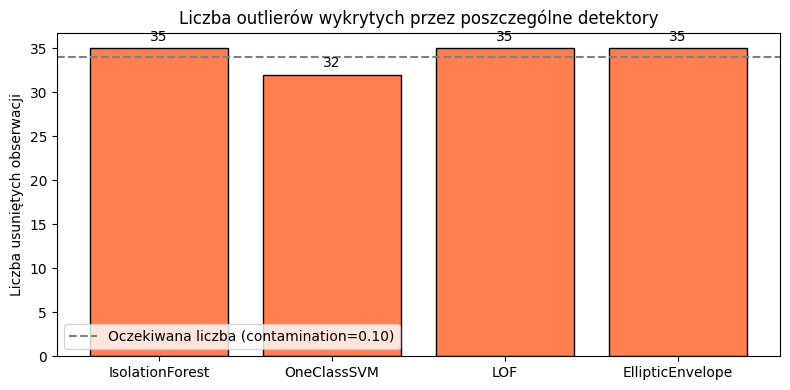

In [6]:
def clean_with_detector(X, y, detector, detector_name):
    """
    Usuwa obserwacje uznane za odstające przez detektor.
    Zwraca oczyszczone X i y.
    """
    if detector_name == 'LOF':
        labels = detector.fit_predict(X)
    else:
        detector.fit(X)
        labels = detector.predict(X)

    inlier_mask = labels == 1
    X_clean = X[inlier_mask]
    y_clean = y[inlier_mask]
    removed = np.sum(~inlier_mask)
    print(f"{detector_name}: usunięto {removed} próbek, pozostało {len(X_clean)}")
    return X_clean, y_clean


detectors = {
    'IsolationForest': IsolationForest(contamination=contamination, random_state=42),
    'OneClassSVM': OneClassSVM(nu=contamination, kernel='rbf', gamma='scale'),
    'LOF': LocalOutlierFactor(n_neighbors=20, contamination=contamination, novelty=False),
    'EllipticEnvelope': EllipticEnvelope(contamination=contamination, random_state=42)
}

cleaned_data = {}

for name, detector in detectors.items():
    X_clean, y_clean = clean_with_detector(
        X_train_standard, y_train, detector, name)
    cleaned_data[name] = (X_clean, y_clean)

removed_counts = [np.sum(~np.isin(X_train_standard, X_clean).all(axis=1))
                  if X_train_standard.shape[0] != X_clean.shape[0]
                  else (X_train_standard.shape[0] - len(X_clean))
                  for X_clean, _ in cleaned_data.values()]

fig, ax = plt.subplots(figsize=(8, 4))
detector_names = list(cleaned_data.keys())
bars = ax.bar(detector_names, removed_counts, color='coral', edgecolor='black')
ax.set_ylabel('Liczba usuniętych obserwacji')
ax.set_title('Liczba outlierów wykrytych przez poszczególne detektory')
for bar, count in zip(bars, removed_counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, str(count),
            ha='center', va='bottom')
ax.axhline(y=int(contamination * len(X_train_standard)), color='gray', linestyle='--',
           label=f'Oczekiwana liczba (contamination={contamination:.2f})')
ax.legend()
plt.tight_layout()
plt.show()

cleaned_data['original_data'] = (X_train_standard, y_train)

# Modele

In [7]:
def forecast_regression(model, initial_window, full_series_norm, base_price, use_scaler=False, scaler=None):
    window = len(initial_window)
    buf = list(initial_window)
    preds_norm = []
    for t in range(window, len(full_series_norm)):
        x_raw = np.array(buf[-window:]).reshape(1, -1)
        if use_scaler and scaler:
            x = scaler.transform(x_raw)
        else:
            x = x_raw
        pred = model.predict(x)[0]
        preds_norm.append(pred)
        buf.append(full_series_norm.iloc[t])
    preds = np.array(preds_norm) * base_price
    actuals = full_series_norm.iloc[window:].values * base_price
    return actuals, preds

## Random Forest

In [8]:
results_rf = {}
actuals_rf = {}
preds_rf = {}

for method_name, data in cleaned_data.items():
    print(f"\n{'='*60}")
    print(f"Przetwarzanie danych: {method_name}")
    print(f"{'='*60}")

    X_train, y_train = data

    rf_param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [5, 10],
        'min_samples_leaf': [2, 4]
    }

    rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
    rf_grid = GridSearchCV(
        estimator=rf_base,
        param_grid=rf_param_grid,
        cv=tscv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        verbose=1
    )
    rf_grid.fit(X_train, y_train)

    rf_best = rf_grid.best_estimator_
    actuals, preds = forecast_regression(
        rf_best, initial_window, norm_test, base_price, use_scaler=True, scaler=scaler_standard)

    mae = mean_absolute_error(actuals, preds)
    mape = mean_absolute_percentage_error(actuals, preds) * 100
    mse = mean_squared_error(actuals, preds)
    r2 = r2_score(actuals, preds)
    actuals_rf[method_name] = actuals
    preds_rf[method_name] = preds

    results_rf[method_name] = {
        'MAE': mae,
        'MAPE': mape,
        'MSE': mse,
        'R2': r2,
        'best_params': rf_grid.best_params_
    }

    print(f"  MAE:  {mae:.2f}")
    print(f"  MAPE: {mape:.2f}%")
    print(f"  MSE:  {mse:.2f}")
    print(f"  R²:   {r2:.4f}")
    print(f"  best_params: {rf_grid.best_params_}")


Przetwarzanie danych: IsolationForest
Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  4.22
  MAPE: 2.65%
  MSE:  33.48
  R²:   0.9071
  best_params: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Przetwarzanie danych: OneClassSVM
Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  4.05
  MAPE: 2.56%
  MSE:  30.84
  R²:   0.9144
  best_params: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 100}

Przetwarzanie danych: LOF
Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  4.67
  MAPE: 2.91%
  MSE:  42.51
  R²:   0.8821
  best_params: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Przetwarzanie danych: EllipticEnvelope
Fitting 5 folds for each of 24 candidates, totalling 120 fits
  MAE:  4.31
  MAPE: 2.72%
  MSE:  33.95
  R²:   0.9058
  best_params: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n

## Support Vector Regression

In [9]:
results_svr = {}
actuals_svr = {}
preds_svr = {}

for method_name, data in cleaned_data.items():
    print(f"\n{'='*60}")
    print(f"Przetwarzanie danych: {method_name}")
    print(f"{'='*60}")

    svr_param_grid = {
        'kernel': ['rbf', 'linear'],
        'C': [1, 10, 100],
        'epsilon': [0.05, 0.1],
        'gamma': ['scale', 0.1, 1]
    }

    X_train, y_train = data

    svr_base = SVR()
    svr_grid = GridSearchCV(
        estimator=svr_base,
        param_grid=svr_param_grid,
        cv=tscv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        verbose=1
    )
    svr_grid.fit(X_train, y_train)

    svr_best = svr_grid.best_estimator_
    actuals, preds = forecast_regression(
        svr_best, initial_window, norm_test, base_price,
        use_scaler=True, scaler=scaler_standard
    )

    mae = mean_absolute_error(actuals, preds)
    mape = mean_absolute_percentage_error(actuals, preds) * 100
    mse = mean_squared_error(actuals, preds)
    r2 = r2_score(actuals, preds)
    actuals_svr[method_name] = actuals
    preds_svr[method_name] = preds

    results_svr[method_name] = {
        'MAE': mae,
        'MAPE': mape,
        'MSE': mse,
        'R2': r2,
        'best_params': svr_grid.best_params_
    }

    print(f"  MAE:  {mae:.2f}")
    print(f"  MAPE: {mape:.2f}%")
    print(f"  MSE:  {mse:.2f}")
    print(f"  R²:   {r2:.4f}")
    print(f"  best params: {svr_grid.best_params_}")


Przetwarzanie danych: IsolationForest
Fitting 5 folds for each of 36 candidates, totalling 180 fits
  MAE:  2.68
  MAPE: 1.77%
  MSE:  16.14
  R²:   0.9552
  best params: {'C': 100, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}

Przetwarzanie danych: OneClassSVM
Fitting 5 folds for each of 36 candidates, totalling 180 fits
  MAE:  2.80
  MAPE: 1.84%
  MSE:  17.46
  R²:   0.9516
  best params: {'C': 100, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}

Przetwarzanie danych: LOF
Fitting 5 folds for each of 36 candidates, totalling 180 fits
  MAE:  2.56
  MAPE: 1.68%
  MSE:  15.25
  R²:   0.9577
  best params: {'C': 100, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}

Przetwarzanie danych: EllipticEnvelope
Fitting 5 folds for each of 36 candidates, totalling 180 fits
  MAE:  2.83
  MAPE: 1.86%
  MSE:  17.51
  R²:   0.9514
  best params: {'C': 100, 'epsilon': 0.05, 'gamma': 'scale', 'kernel': 'linear'}

Przetwarzanie danych: original_data
Fitting 5 folds for each o

## K Neighbors Regressor

In [10]:
results_knn = {}
actuals_knn = {}
preds_knn = {}

for method_name, data in cleaned_data.items():
    print(f"\n{'='*60}")
    print(f"Przetwarzanie danych: {method_name}")
    print(f"{'='*60}")

    knn_param_grid = {
        'n_neighbors': [3, 5, 7, 9, 11, 15],
        'weights': ['uniform', 'distance'],
        'p': [1, 2],
        'algorithm': ['auto', 'ball_tree', 'kd_tree']
    }

    knn_base = KNeighborsRegressor()
    knn_grid = GridSearchCV(
        estimator=knn_base,
        param_grid=knn_param_grid,
        cv=tscv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        verbose=1
    )

    X_train, y_train = data
    knn_grid.fit(X_train, y_train)

    knn_best = knn_grid.best_estimator_
    actuals, preds = forecast_regression(
        knn_best, initial_window, norm_test, base_price,
        use_scaler=True, scaler=scaler_standard
    )

    mae = mean_absolute_error(actuals, preds)
    mape = mean_absolute_percentage_error(actuals, preds) * 100
    mse = mean_squared_error(actuals, preds)
    r2 = r2_score(actuals, preds)
    actuals_knn[method_name] = actuals
    preds_knn[method_name] = preds

    results_knn[method_name] = {
        'MAE': mae,
        'MAPE': mape,
        'MSE': mse,
        'R2': r2,
        'best_params': knn_grid.best_params_
    }

    print(f"  MAE:  {mae:.2f}")
    print(f"  MAPE: {mape:.2f}%")
    print(f"  MSE:  {mse:.2f}")
    print(f"  R²:   {r2:.4f}")
    print(f"  best params: {knn_grid.best_params_}")


Przetwarzanie danych: IsolationForest
Fitting 5 folds for each of 72 candidates, totalling 360 fits
  MAE:  7.50
  MAPE: 4.83%
  MSE:  87.90
  R²:   0.7561
  best params: {'algorithm': 'auto', 'n_neighbors': 15, 'p': 2, 'weights': 'distance'}

Przetwarzanie danych: OneClassSVM
Fitting 5 folds for each of 72 candidates, totalling 360 fits
  MAE:  7.35
  MAPE: 4.79%
  MSE:  88.34
  R²:   0.7549
  best params: {'algorithm': 'auto', 'n_neighbors': 7, 'p': 2, 'weights': 'distance'}

Przetwarzanie danych: LOF
Fitting 5 folds for each of 72 candidates, totalling 360 fits
  MAE:  7.97
  MAPE: 5.15%
  MSE:  96.85
  R²:   0.7313
  best params: {'algorithm': 'auto', 'n_neighbors': 11, 'p': 2, 'weights': 'distance'}

Przetwarzanie danych: EllipticEnvelope
Fitting 5 folds for each of 72 candidates, totalling 360 fits
  MAE:  7.89
  MAPE: 5.07%
  MSE:  94.28
  R²:   0.7384
  best params: {'algorithm': 'auto', 'n_neighbors': 15, 'p': 2, 'weights': 'distance'}

Przetwarzanie danych: original_data
Fit

## Neural Network

In [ ]:
def build_nn_model(layers, activations='relu', dropout_rate=0.3, learning_rate=0.001):
    """
    Buduje sieć neuronową na podstawie listy warstw.

    Parametry:
        layers: lista liczb całkowitych – liczba neuronów w kolejnych warstwach ukrytych.
                Np. [5,10,15,10,5] stworzy 5 warstw ukrytych.
        activations: funkcja aktywacji dla wszystkich warstw (str) lub lista takich samych
                     długości jak layers, określająca aktywację dla każdej warstwy.
        dropout_rate: współczynnik dropoutu (dodawany po każdej warstwie ukrytej).
        learning_rate: szybkość uczenia.
    """
    model = Sequential()
    model.add(Input(shape=(WINDOW,)))

    if isinstance(activations, str):
        act_list = [activations] * len(layers)
    else:
        act_list = activations
        if len(act_list) != len(layers):
            raise ValueError(
                "Długość listy aktywacji musi być równa liczbie warstw.")

    for i, units in enumerate(layers):
        model.add(Dense(units, activation=act_list[i]))
        if i < len(layers) - 1: 
            model.add(Dropout(dropout_rate))

    model.add(Dense(1))

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )
    return model


def forecast_nn(model, scaler, initial_window_norm, full_series_norm, base_price):
    window = len(initial_window_norm)
    buf = list(initial_window_norm)
    preds_norm = []

    for t in range(window, len(full_series_norm)):
        x_raw = np.array(buf[-window:]).reshape(1, -1)
        x_scaled = scaler.transform(x_raw)
        pred = model.predict(x_scaled, verbose=0)[0, 0]
        preds_norm.append(pred)
        buf.append(full_series_norm.iloc[t])

    preds = np.array(preds_norm) * base_price
    actuals = full_series_norm.iloc[window:].values * base_price
    return actuals, preds

In [12]:
results_nn = {}
actuals_nn = {}
preds_nn = {}

for method_name, data in cleaned_data.items():
    print(f"\n{'='*60}")
    print(f"Przetwarzanie danych: {method_name}")
    print(f"{'='*60}")

    nn_configs = [
        {'layers': [64, 32, 16], 'dropout': 0.3,
            'lr': 0.001, 'activations': 'relu'},
        {'layers': [128, 64, 32, 16], 'dropout': 0.2, 'lr': 0.001,
            'activations': ['elu', 'elu', 'elu', 'relu']},
        {'layers': [8, 16, 32, 64, 32, 16, 8], 'dropout': 0.2,
            'lr': 0.0005, 'activations': 'relu'},
        {'layers': [32, 32, 32, 32, 32], 'dropout': 0.4,
            'lr': 0.001, 'activations': 'leaky_relu'},
    ]

    best_nn_mae = float('inf')
    best_nn_config = None
    best_nn_model = None

    X_train, y_train = data

    for config in nn_configs:
        clear_session()
        print(f"Testowanie: {config}")
        nn_model = build_nn_model(
            layers=config['layers'],
            activations=config.get('activations', 'relu'),
            dropout_rate=config['dropout'],
            learning_rate=config['lr']
        )
        early_stop = EarlyStopping(
            monitor='val_loss', patience=15, restore_best_weights=True)

        nn_model.fit(
            X_train, y_train,
            epochs=150, batch_size=32, validation_split=0.1,
            callbacks=[early_stop], verbose=0
        )

        val_preds = nn_model.predict(X_train[-100:], verbose=0)
        val_mae = mean_absolute_error(y_train[-100:], val_preds.flatten())
        print(f"  Val MAE: {val_mae:.4f}")

        if val_mae < best_nn_mae:
            best_nn_mae = val_mae
            best_nn_config = config
            best_nn_model = nn_model

    actuals, preds = forecast_nn(
        best_nn_model, scaler_standard, initial_window, norm_test, base_price)

    mae = mean_absolute_error(actuals, preds)
    mape = mean_absolute_percentage_error(actuals, preds) * 100
    mse = mean_squared_error(actuals, preds)
    r2 = r2_score(actuals, preds)
    actuals_nn[method_name] = actuals
    preds_nn[method_name] = preds

    results_nn[method_name] = {
        'MAE': mae,
        'MAPE': mape,
        'MSE': mse,
        'R2': r2,
        'best_params': best_nn_config
    }

    print(f"  MAE:  {mae:.2f}")
    print(f"  MAPE: {mape:.2f}%")
    print(f"  MSE:  {mse:.2f}")
    print(f"  R²:   {r2:.4f}")
    print(f"  best params: {best_nn_config}")


Przetwarzanie danych: IsolationForest
Testowanie: {'layers': [64, 32, 16], 'dropout': 0.3, 'lr': 0.001, 'activations': 'relu'}
  Val MAE: 0.1796
Testowanie: {'layers': [128, 64, 32, 16], 'dropout': 0.2, 'lr': 0.001, 'activations': ['elu', 'elu', 'elu', 'relu']}
  Val MAE: 0.1285
Testowanie: {'layers': [8, 16, 32, 64, 32, 16, 8], 'dropout': 0.2, 'lr': 0.0005, 'activations': 'relu'}


  Val MAE: 0.3367
Testowanie: {'layers': [32, 32, 32, 32, 32], 'dropout': 0.4, 'lr': 0.001, 'activations': 'leaky_relu'}
  Val MAE: 1.2340
  MAE:  16.42
  MAPE: 10.81%
  MSE:  355.46
  R²:   0.0137
  best params: {'layers': [128, 64, 32, 16], 'dropout': 0.2, 'lr': 0.001, 'activations': ['elu', 'elu', 'elu', 'relu']}

Przetwarzanie danych: OneClassSVM
Testowanie: {'layers': [64, 32, 16], 'dropout': 0.3, 'lr': 0.001, 'activations': 'relu'}
  Val MAE: 0.1136
Testowanie: {'layers': [128, 64, 32, 16], 'dropout': 0.2, 'lr': 0.001, 'activations': ['elu', 'elu', 'elu', 'relu']}
  Val MAE: 0.1166
Testowanie: {'layers': [8, 16, 32, 64, 32, 16, 8], 'dropout': 0.2, 'lr': 0.0005, 'activations': 'relu'}
  Val MAE: 0.3388
Testowanie: {'layers': [32, 32, 32, 32, 32], 'dropout': 0.4, 'lr': 0.001, 'activations': 'leaky_relu'}
  Val MAE: 0.1683
  MAE:  9.48
  MAPE: 6.32%
  MSE:  138.29
  R²:   0.6163
  best params: {'layers': [64, 32, 16], 'dropout': 0.3, 'lr': 0.001, 'activations': 'relu'}

Przetwarzani

## Naiwny

In [13]:
results_dummy = {}
actuals_dummy = {}
preds_dummy = {}

for method_name, data in cleaned_data.items():
    print(f"\n{'='*60}")
    print(f"Przetwarzanie danych: {method_name}")
    print(f"{'='*60}")

    X_train, y_train = data
    preds = y_train[:-1]
    actuals = y_train[1:]

    mae = mean_absolute_error(actuals, preds)
    mape = mean_absolute_percentage_error(actuals, preds) * 100
    mse = mean_squared_error(actuals, preds)
    r2 = r2_score(actuals, preds)
    actuals_dummy[method_name] = actuals
    preds_dummy[method_name] = preds

    results_dummy[method_name] = {
        'MAE': mae,
        'MAPE': mape,
        'MSE': mse,
        'R2': r2,
    }

    print(f"  MAE:  {mae:.2f}")
    print(f"  MAPE: {mape:.2f}%")
    print(f"  MSE:  {mse:.2f}")
    print(f"  R²:   {r2:.4f}")


Przetwarzanie danych: IsolationForest
  MAE:  0.06
  MAPE: 1.88%
  MSE:  0.05
  R²:   0.9172

Przetwarzanie danych: OneClassSVM
  MAE:  0.06
  MAPE: 1.83%
  MSE:  0.04
  R²:   0.9345

Przetwarzanie danych: LOF
  MAE:  0.05
  MAPE: 1.68%
  MSE:  0.04
  R²:   0.9450

Przetwarzanie danych: EllipticEnvelope
  MAE:  0.05
  MAPE: 1.64%
  MSE:  0.04
  R²:   0.9519

Przetwarzanie danych: original_data
  MAE:  0.05
  MAPE: 1.66%
  MSE:  0.03
  R²:   0.9668


## System Ekspercki

In [14]:
def build_fuzzy_expert():
    cena = ctrl.Antecedent(np.arange(0, 301, 1), 'cena')
    delta = ctrl.Antecedent(np.arange(-50, 51, 1), 'delta')
    decyzja = ctrl.Consequent(np.arange(-1, 1.01, 0.01), 'decyzja')

    cena['niska'] = fuzz.trimf(cena.universe, [0, 0, 120])
    cena['srednia'] = fuzz.trimf(cena.universe, [100, 150, 200])
    cena['wysoka'] = fuzz.trimf(cena.universe, [170, 250, 300])

    delta['spadnie'] = fuzz.trimf(delta.universe, [-50, -15, 0])
    delta['stabilna'] = fuzz.trimf(delta.universe, [-5, 0, 5])
    delta['wzrosnie'] = fuzz.trimf(delta.universe, [0, 15, 50])

    decyzja['sprzedaj'] = fuzz.trimf(decyzja.universe, [-1, -1, -0.2])
    decyzja['trzymaj'] = fuzz.trimf(decyzja.universe, [-0.3, 0, 0.3])
    decyzja['kup'] = fuzz.trimf(decyzja.universe, [0.2, 1, 1])

    rules = [
        ctrl.Rule(cena['niska'] & delta['wzrosnie'], decyzja['kup']),
        ctrl.Rule(cena['wysoka'] & delta['spadnie'], decyzja['sprzedaj']),
        ctrl.Rule(cena['srednia'] & delta['wzrosnie'], decyzja['kup']),
        ctrl.Rule(cena['srednia'] & delta['spadnie'], decyzja['sprzedaj']),
        ctrl.Rule(cena['niska'] & delta['spadnie'], decyzja['trzymaj']),
        ctrl.Rule(cena['wysoka'] & ~delta['spadnie'], decyzja['trzymaj']),
        ctrl.Rule(cena['niska'] & delta['stabilna'], decyzja['kup']),
        ctrl.Rule(cena['srednia'] & delta['stabilna'], decyzja['trzymaj']),
        ctrl.Rule(cena['wysoka'] & delta['stabilna'], decyzja['sprzedaj']),
    ]

    expert_ctrl = ctrl.ControlSystem(rules)
    return ctrl.ControlSystemSimulation(expert_ctrl)

In [15]:
import pandas as pd

rows = []

for model_name in cleaned_data.keys():
    n_days = len(preds_rf[model_name])

    for day in range(n_days):
        rows.append({
            'model': model_name,
            'day': day + 1,
            'pred_rf': preds_rf[model_name][day],
            'pred_knn': preds_knn[model_name][day],
            'pred_svr': preds_svr[model_name][day],
            'pred_nn': preds_nn[model_name][day]
        })

models_df = pd.DataFrame(rows)

In [16]:
test_raw = leagues[test_idx].loc[ITEM].dropna()
prices = test_raw.values

simulation_days = 86
start_day = WINDOW
end_day = min(start_day + simulation_days, len(prices))

print(f"\n{'='*60}")
print(f"SYMULACJA SYSTEMU EKSPERCKIEGO - {ITEM}")
print(
    f"Liga testowa: {['Necropolis', 'Affliction', 'Settlers', 'Mercenaries', 'Keepers'][test_idx]}")
print(f"Dni: {start_day+1} → {end_day}")
print(f"{'='*60}")

anomaly_models = ['IsolationForest', 'OneClassSVM', 'LOF', 'EllipticEnvelope']

daily_avg_all = (
    models_df[models_df['model'].isin(anomaly_models)]
    .groupby('day')[['pred_rf', 'pred_knn', 'pred_svr', 'pred_nn']]
    .mean()
    .mean(axis=1)
    .to_dict()
)

expert = build_fuzzy_expert()

decisions_log = []
for t in range(start_day, end_day):
    current_price = prices[t]
    day_num = t - start_day + 1

    prognoza_value = daily_avg_all.get(day_num)
    if prognoza_value is None:
        prognoza_value = prices[t - WINDOW:t].mean()

    expert.input['cena'] = current_price
    expert.input['delta'] = prognoza_value - current_price

    try:
        expert.compute()
        decision_value = expert.output['decyzja']
    except (KeyError, ValueError):
        decision_value = 0.0

    if decision_value > 0.15:
        decision_text = "KUP"
    elif decision_value < -0.15:
        decision_text = "SPRZEDAJ"
    else:
        decision_text = "TRZYMAJ"

    decisions_log.append(
        (t + 1, current_price, prognoza_value, decision_value, decision_text))

print(f"\n{'Dzień':<6} {'Cena':<12} {'Prognoza':<12} {'Wartość':<10} {'Decyzja':<10}")
print("-" * 50)
for day, price, prog, val, dec in decisions_log:
    print(f"{day:<6} {price:<12.2f} {prog:<12.2f} {val:<10.2f} {dec:<10}")

decisions_array = np.array([d[4] for d in decisions_log])
unique, counts = np.unique(decisions_array, return_counts=True)
print(f"\n--- PODSUMOWANIE ---")
for dec, cnt in zip(unique, counts):
    print(f"  {dec}: {cnt} razy ({cnt/len(decisions_array)*100:.1f}%)")


SYMULACJA SYSTEMU EKSPERCKIEGO - Divine Orb
Liga testowa: Keepers
Dni: 15 → 100

Dzień  Cena         Prognoza     Wartość    Decyzja   
--------------------------------------------------
15     115.90       124.83       0.66       KUP       
16     108.00       119.68       0.63       KUP       
17     108.00       113.36       0.63       KUP       
18     114.00       111.38       -0.19      SPRZEDAJ  
19     115.15       115.92       0.12       TRZYMAJ   
20     116.35       116.28       0.06       TRZYMAJ   
21     123.00       114.95       -0.68      SPRZEDAJ  
22     129.20       119.32       -0.70      SPRZEDAJ  
23     135.00       126.06       -0.70      SPRZEDAJ  
24     138.40       133.55       -0.61      SPRZEDAJ  
25     150.00       136.68       -0.73      SPRZEDAJ  
26     150.00       147.84       -0.19      SPRZEDAJ  
27     150.00       149.65       -0.03      TRZYMAJ   
28     150.00       149.88       -0.01      TRZYMAJ   
29     150.00       150.08       0.01     

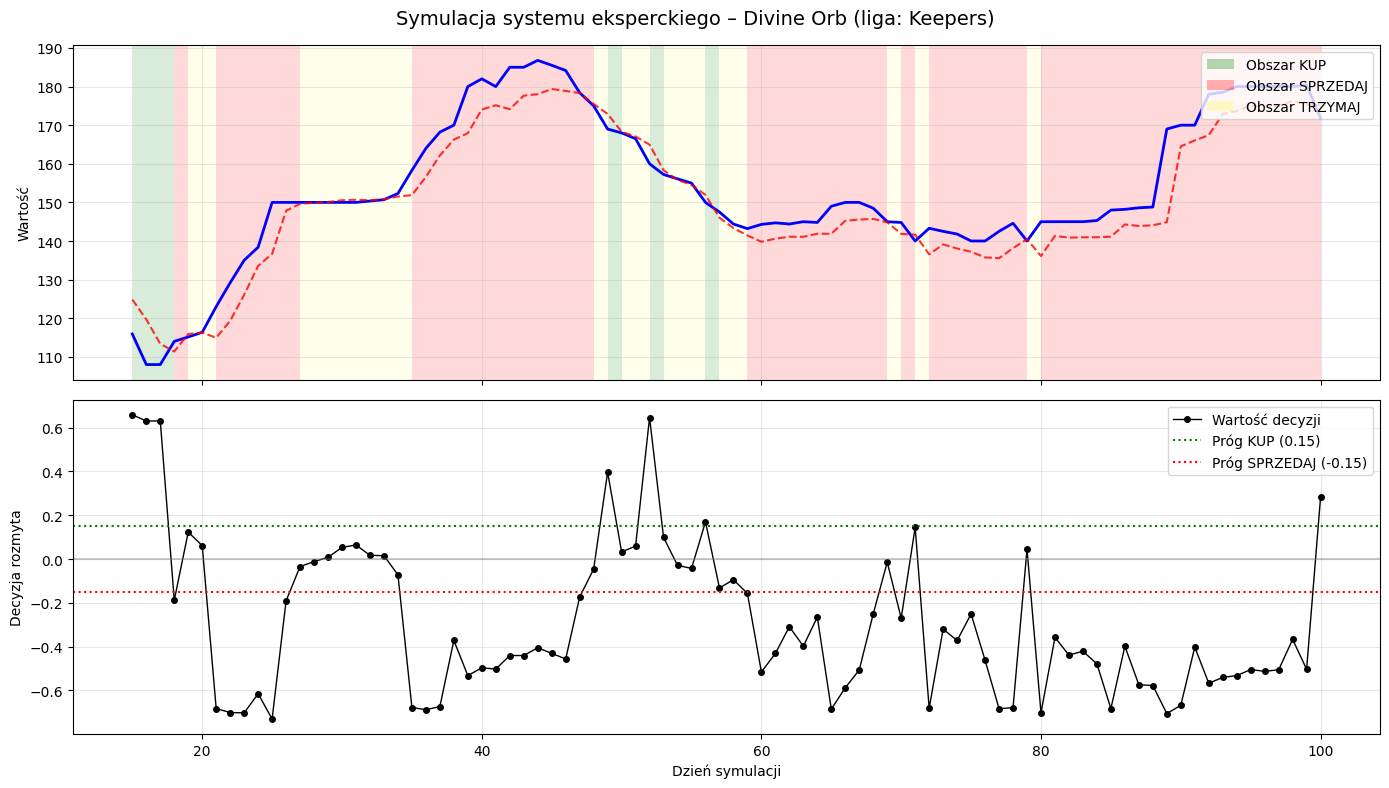

In [17]:
from matplotlib.patches import Patch
import matplotlib.pyplot as plt

days = [d[0] for d in decisions_log]
prices_sim = [d[1] for d in decisions_log]
prognozy = [d[2] for d in decisions_log]
decision_values = [d[3] for d in decisions_log]
decision_texts = [d[4]
                  for d in decisions_log]

liga_nazwa = ['Necropolis', 'Affliction',
              'Settlers', 'Mercenaries', 'Keepers'][test_idx]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle(
    f'Symulacja systemu eksperckiego – {ITEM} (liga: {liga_nazwa})', fontsize=14)

ax1.plot(days, prices_sim, 'b-', linewidth=2, label='Cena rzeczywista')
ax1.plot(days, prognozy, 'r--', linewidth=1.5,
         alpha=0.8, label='Prognoza (średnia z modeli)')
ax1.set_ylabel('Wartość')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

for i in range(len(days) - 1):
    if decision_texts[i] == 'KUP':
        kolor, alfa = 'green', 0.15
    elif decision_texts[i] == 'SPRZEDAJ':
        kolor, alfa = 'red', 0.15
    else:
        kolor, alfa = 'yellow', 0.08
    ax1.axvspan(days[i], days[i+1], facecolor=kolor, alpha=alfa)

legend_elements = [Patch(facecolor='green', alpha=0.3, label='Obszar KUP'),
                   Patch(facecolor='red', alpha=0.3, label='Obszar SPRZEDAJ'),
                   Patch(facecolor='yellow', alpha=0.2, label='Obszar TRZYMAJ')]
ax1.legend(handles=legend_elements, loc='upper right')

ax2.plot(days, decision_values, 'ko-', markersize=4,
         linewidth=1, label='Wartość decyzji')
ax2.axhline(0.15, color='green', linestyle=':',
            linewidth=1.5, label='Próg KUP (0.15)')
ax2.axhline(-0.15, color='red', linestyle=':',
            linewidth=1.5, label='Próg SPRZEDAJ (-0.15)')
ax2.axhline(0, color='gray', linestyle='-', alpha=0.4)
ax2.set_ylabel('Decyzja rozmyta')
ax2.set_xlabel('Dzień symulacji')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Podsumowanie

In [21]:
all_experiments = {
    'Random Forest': results_rf,
    'SVR': results_svr,
    'KNN': results_knn,
    'Sieć neuronowa': results_nn,
}

rows = []
for exp_name, models_dict in all_experiments.items():
    for model_name, metrics in models_dict.items():
        params = metrics.get('best_params', '')
        if not isinstance(params, str):
            params = str(params)
        rows.append({
            'Eksperyment': exp_name,
            'Model': model_name,
            'MAE': metrics['MAE'],
            'MAPE': metrics['MAPE'],
            'MSE': metrics['MSE'],
            'R²': metrics['R2'],
            'Najlepsze parametry': params
        })

df = pd.DataFrame(rows)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:.4f}'.format)

print(df.to_string(index=False))

print("\n" + "="*80)
print("NAJLEPSZE WYNIKI")
print("="*80)

metrics_to_minimize = ['MAE', 'MAPE', 'MSE']
metrics_to_maximize = ['R²']

# Metryki minimalizowane
for metric in metrics_to_minimize:
    best_row = df.loc[df[metric].idxmin()]

    print(f"\nNajlepszy wynik dla {metric}:")
    print(f"  Eksperyment: {best_row['Eksperyment']}")
    print(f"  Model detekcji anomalii: {best_row['Model']}")
    print(f"  Wartość {metric}: {best_row[metric]:.4f}")

# Metryki maksymalizowane
for metric in metrics_to_maximize:
    best_row = df.loc[df[metric].idxmax()]

    print(f"\nNajlepszy wynik dla {metric}:")
    print(f"  Eksperyment: {best_row['Eksperyment']}")
    print(f"  Model detekcji anomalii: {best_row['Model']}")
    print(f"  Wartość {metric}: {best_row[metric]:.4f}")

   Eksperyment            Model     MAE    MAPE      MSE     R²                                                                                      Najlepsze parametry
 Random Forest  IsolationForest  4.2183  2.6492  33.4782 0.9071                    {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
 Random Forest      OneClassSVM  4.0525  2.5586  30.8388 0.9144                  {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 100}
 Random Forest              LOF  4.6732  2.9058  42.5053 0.8821                    {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
 Random Forest EllipticEnvelope  4.3143  2.7161  33.9479 0.9058                    {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
 Random Forest    original_data  4.0066  2.5183  31.3055 0.9131                    {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_esti

## Wizualizacja

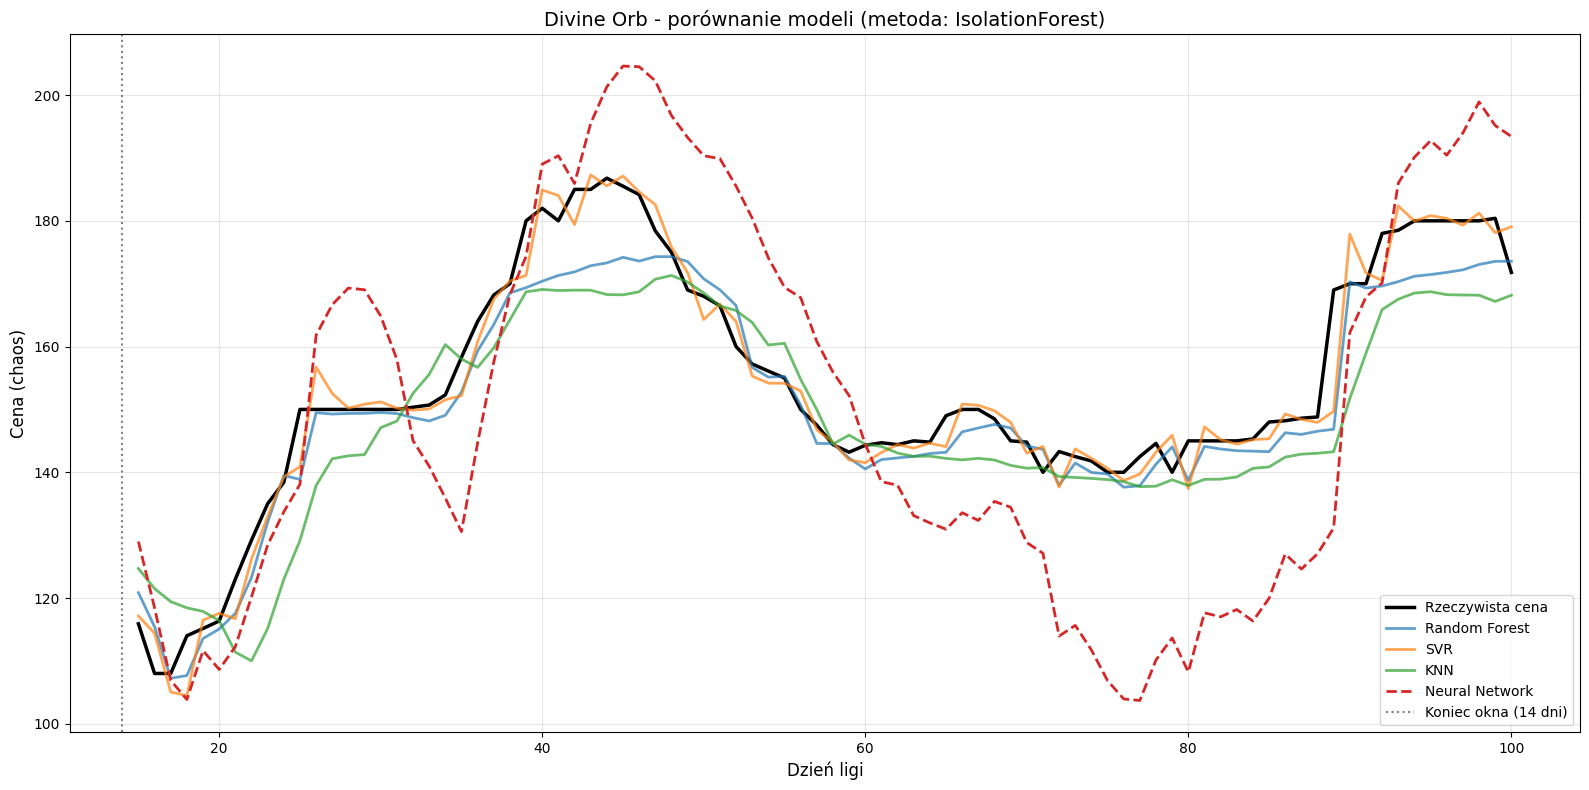

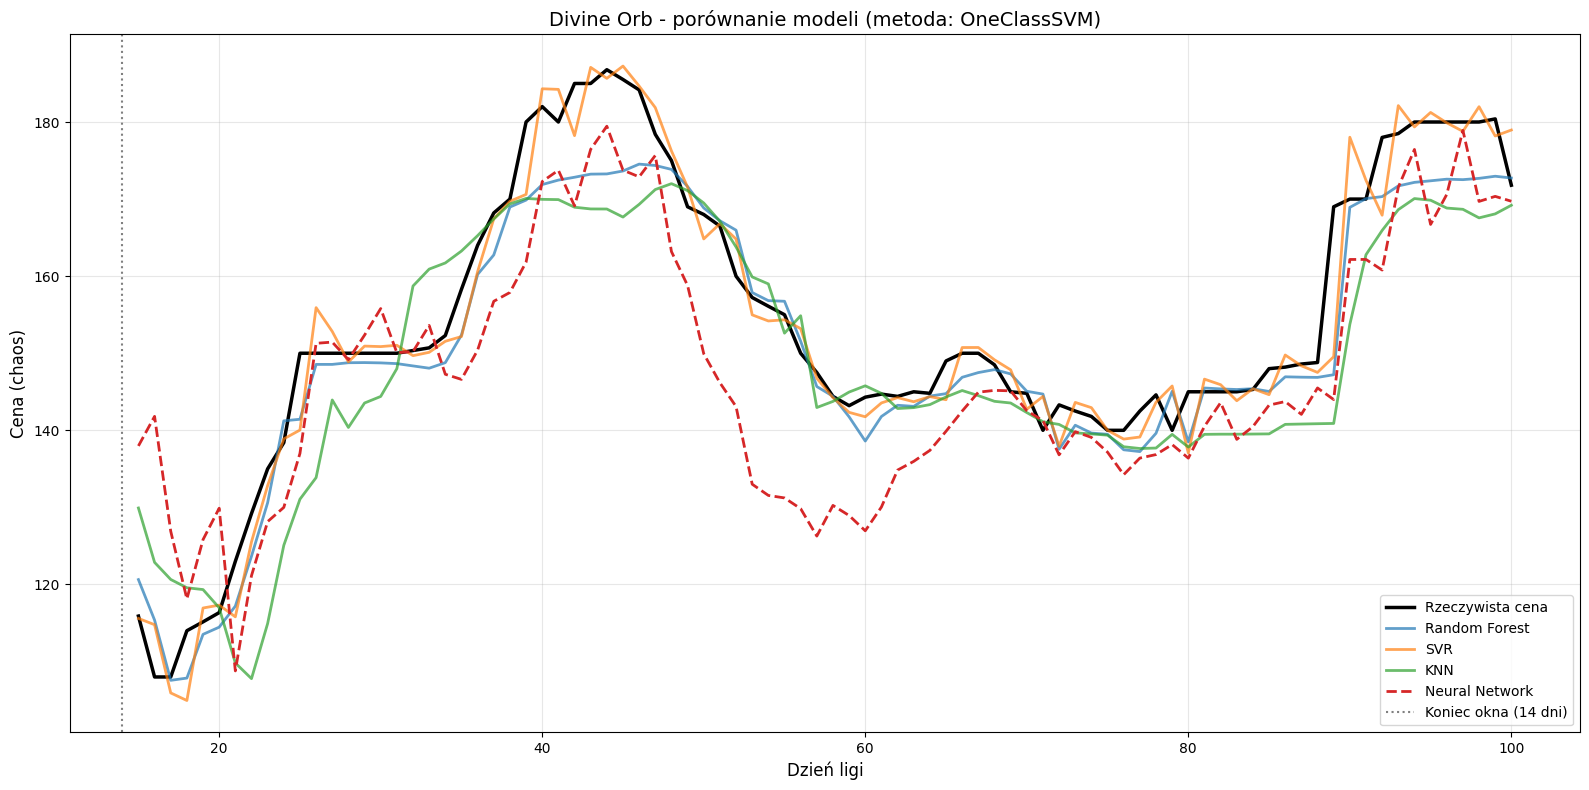

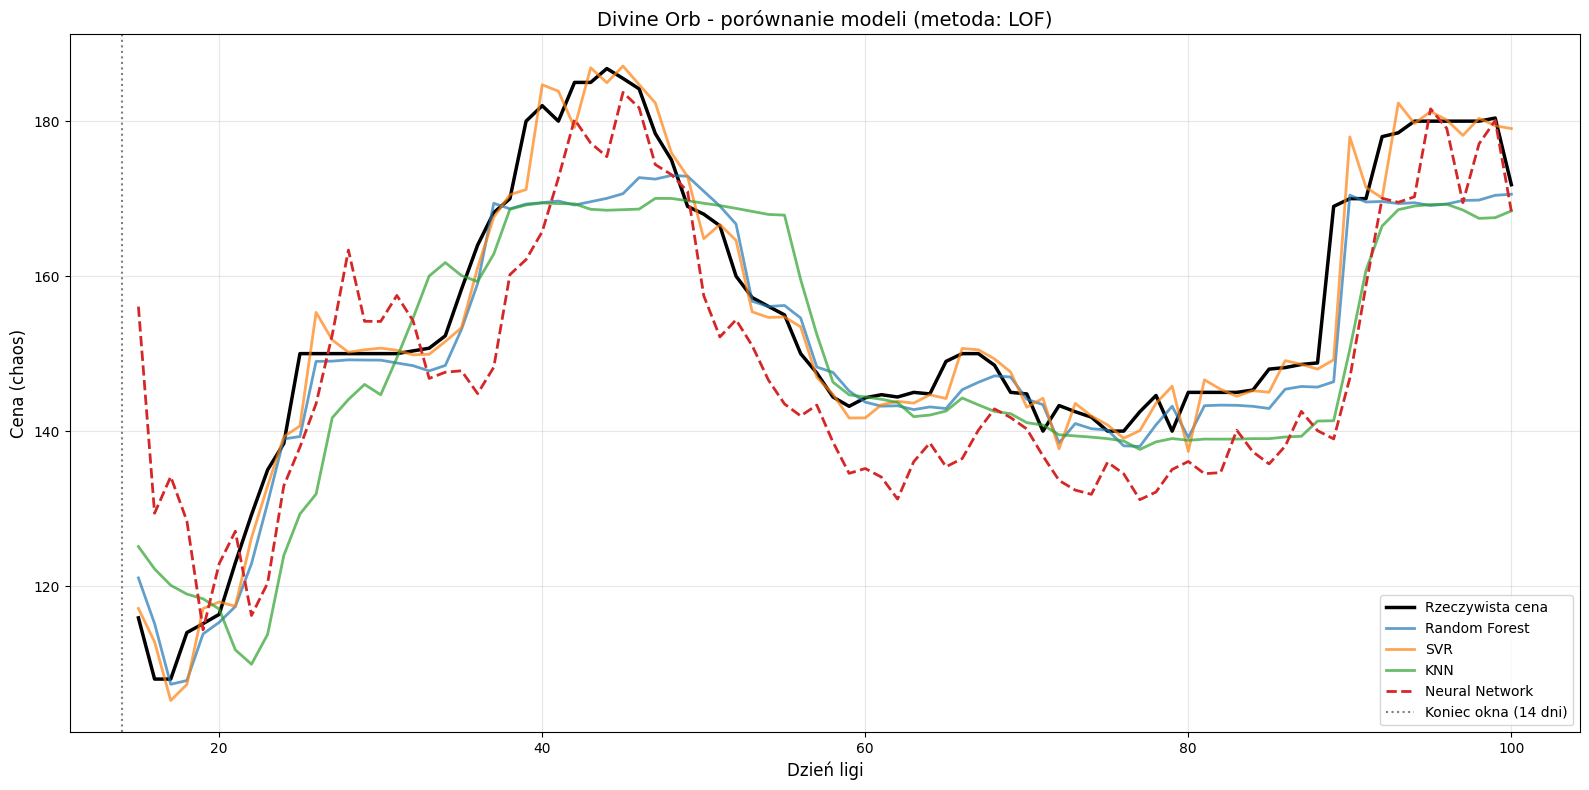

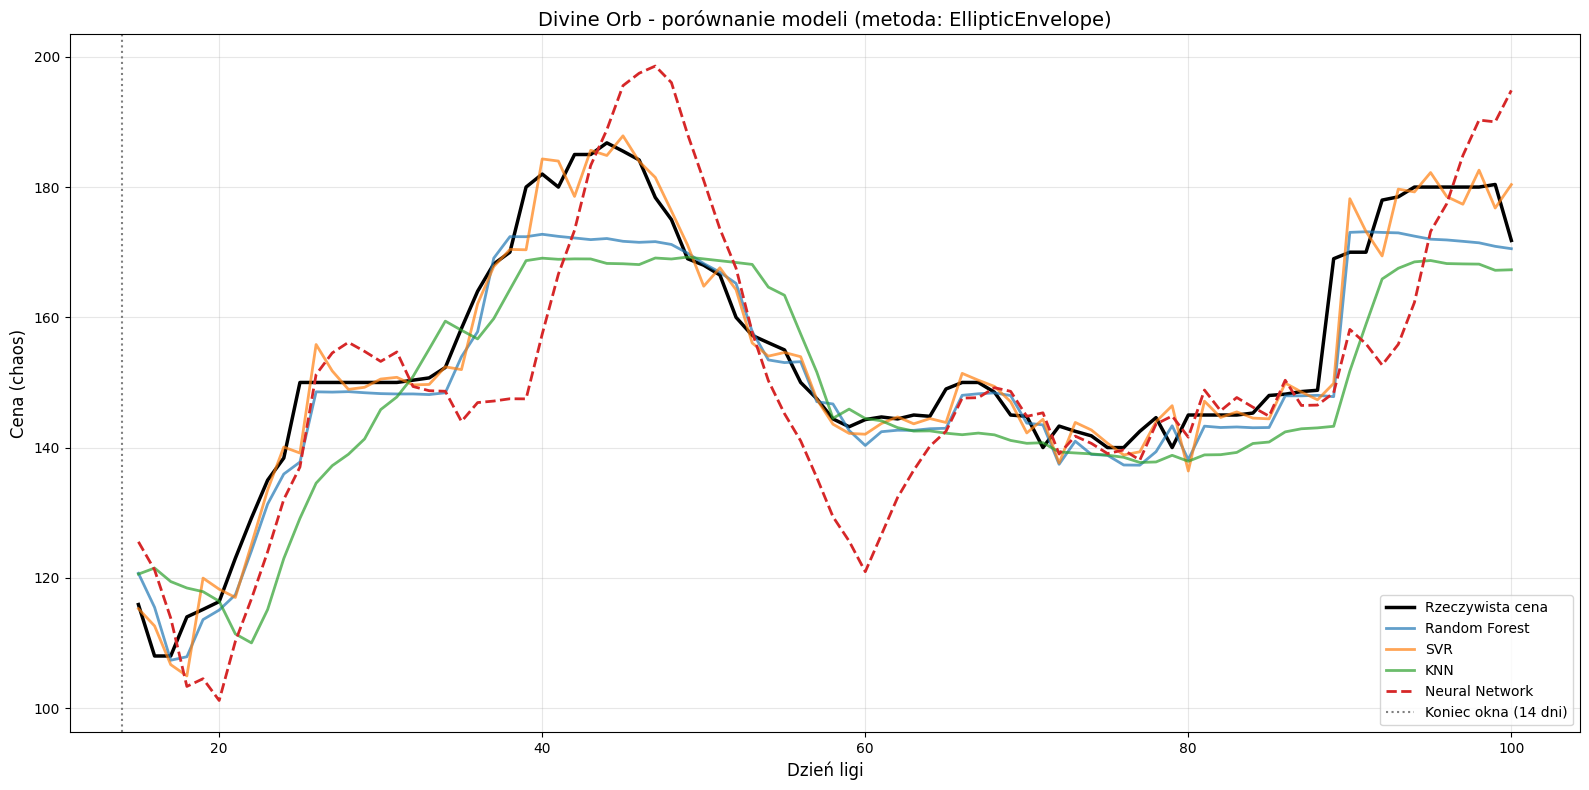

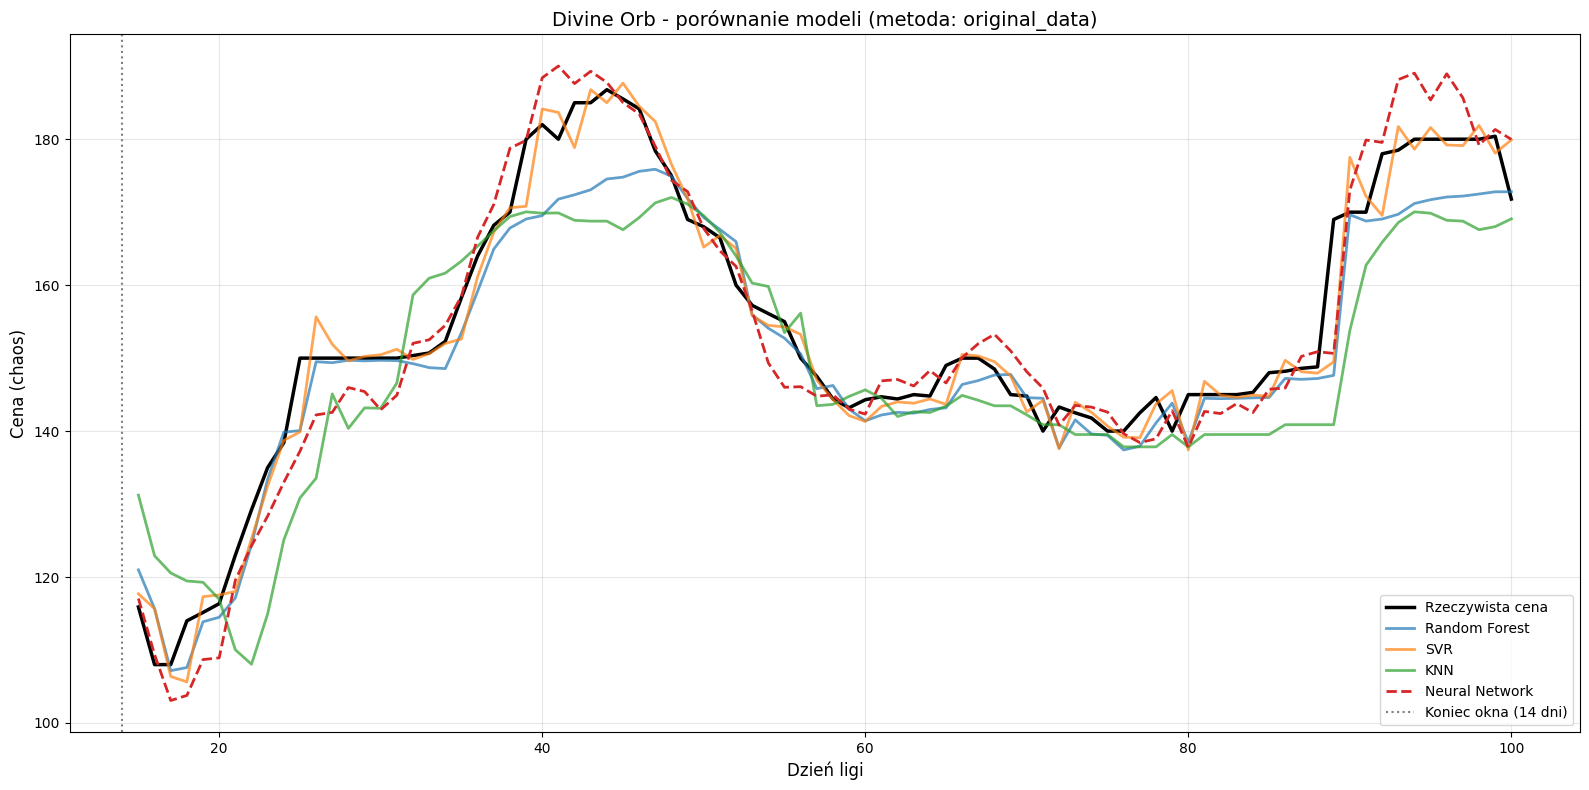

In [19]:
n_test = len(actuals_nn['IsolationForest'])
days_preds = range(WINDOW + 1, WINDOW + n_test + 1)

models = [
    ('Random Forest',   preds_rf),
    ('SVR',             preds_svr),
    ('KNN',             preds_knn),
    ('Neural Network',  preds_nn)
]

model_styles = {
    'Random Forest':    {'alpha': 0.7, 'linewidth': 2},
    'SVR':              {'alpha': 0.7, 'linewidth': 2},
    'KNN':              {'alpha': 0.7, 'linewidth': 2},
    'Neural Network':   {'linestyle': '--', 'linewidth': 2}
}

for method in preds_rf.keys():
    plt.figure(figsize=(16, 8))
    plt.plot(days_preds, actuals_nn[method], label='Rzeczywista cena',
             color='black', lw=2.5)

    for model_name, pred_dict in models:
        style = model_styles[model_name]
        plt.plot(days_preds, pred_dict[method], label=model_name, **style)

    plt.axvline(x=WINDOW, color='gray', linestyle=':',
                label=f'Koniec okna ({WINDOW} dni)')
    plt.title(f'{ITEM} - porównanie modeli (metoda: {method})', fontsize=14)
    plt.xlabel('Dzień ligi', fontsize=12)
    plt.ylabel('Cena (chaos)', fontsize=12)
    plt.legend(loc='best')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

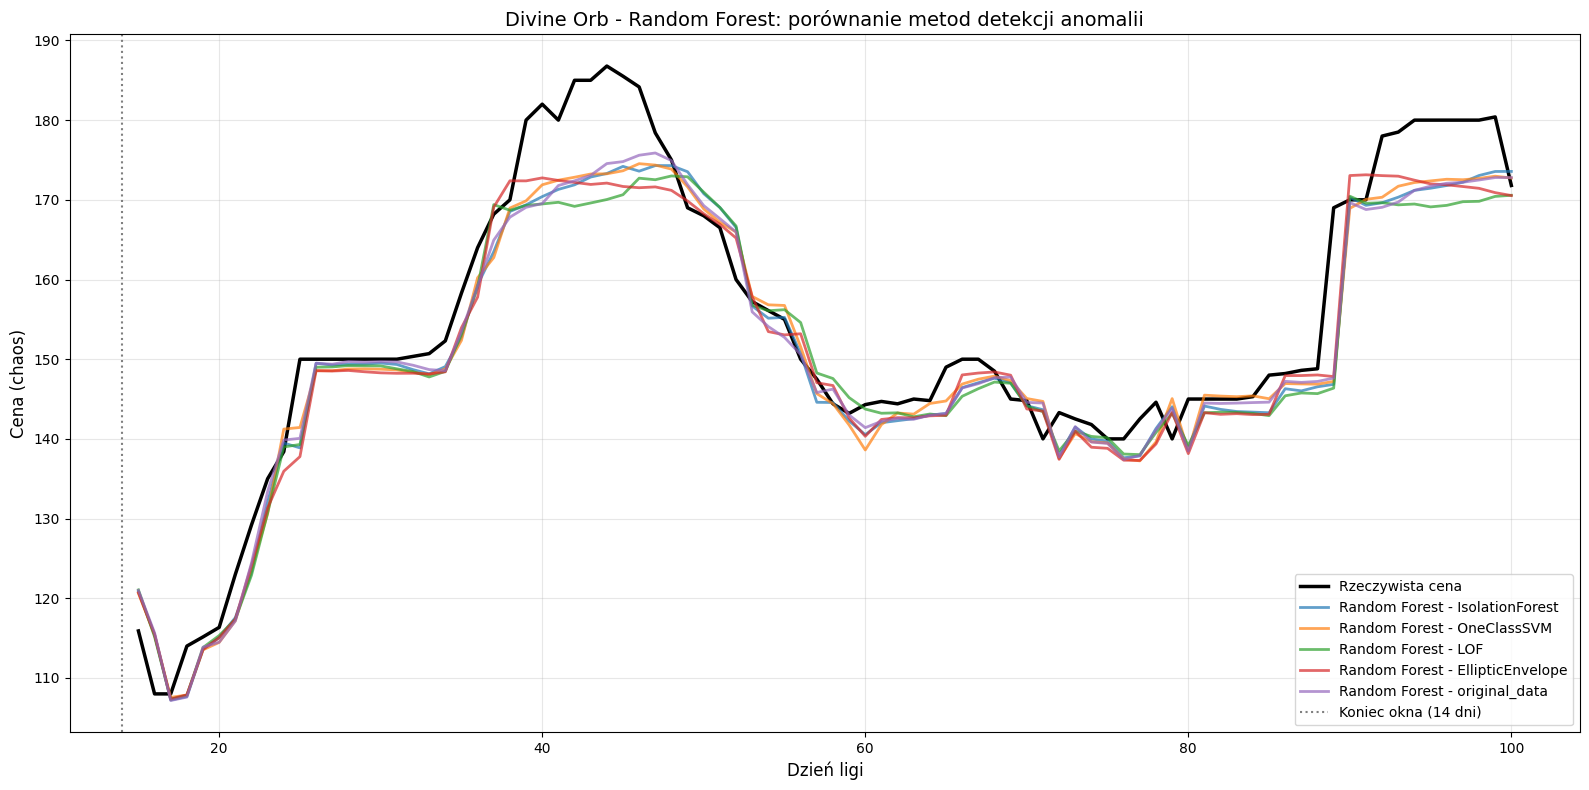

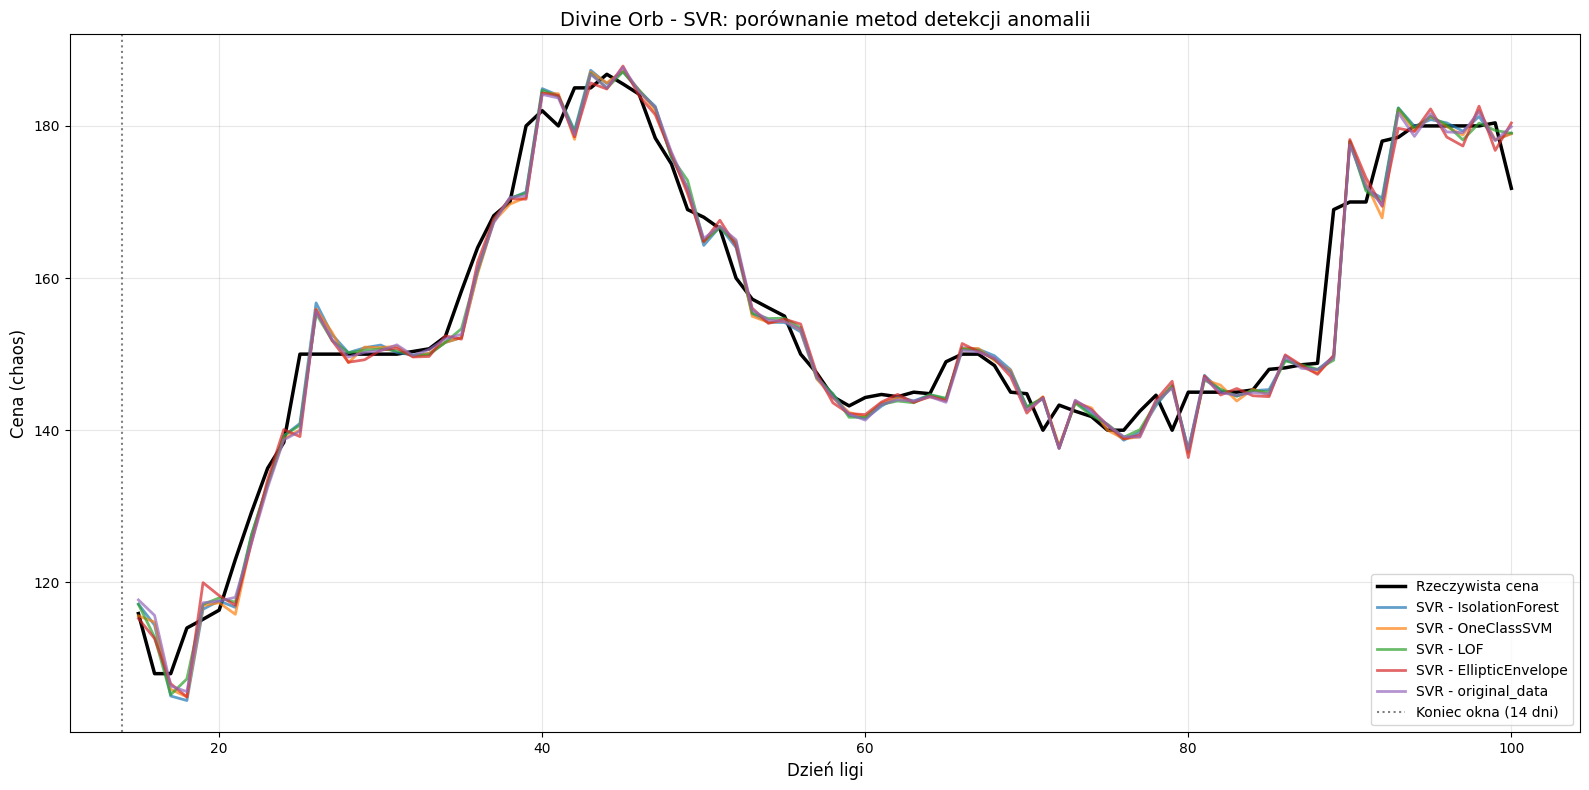

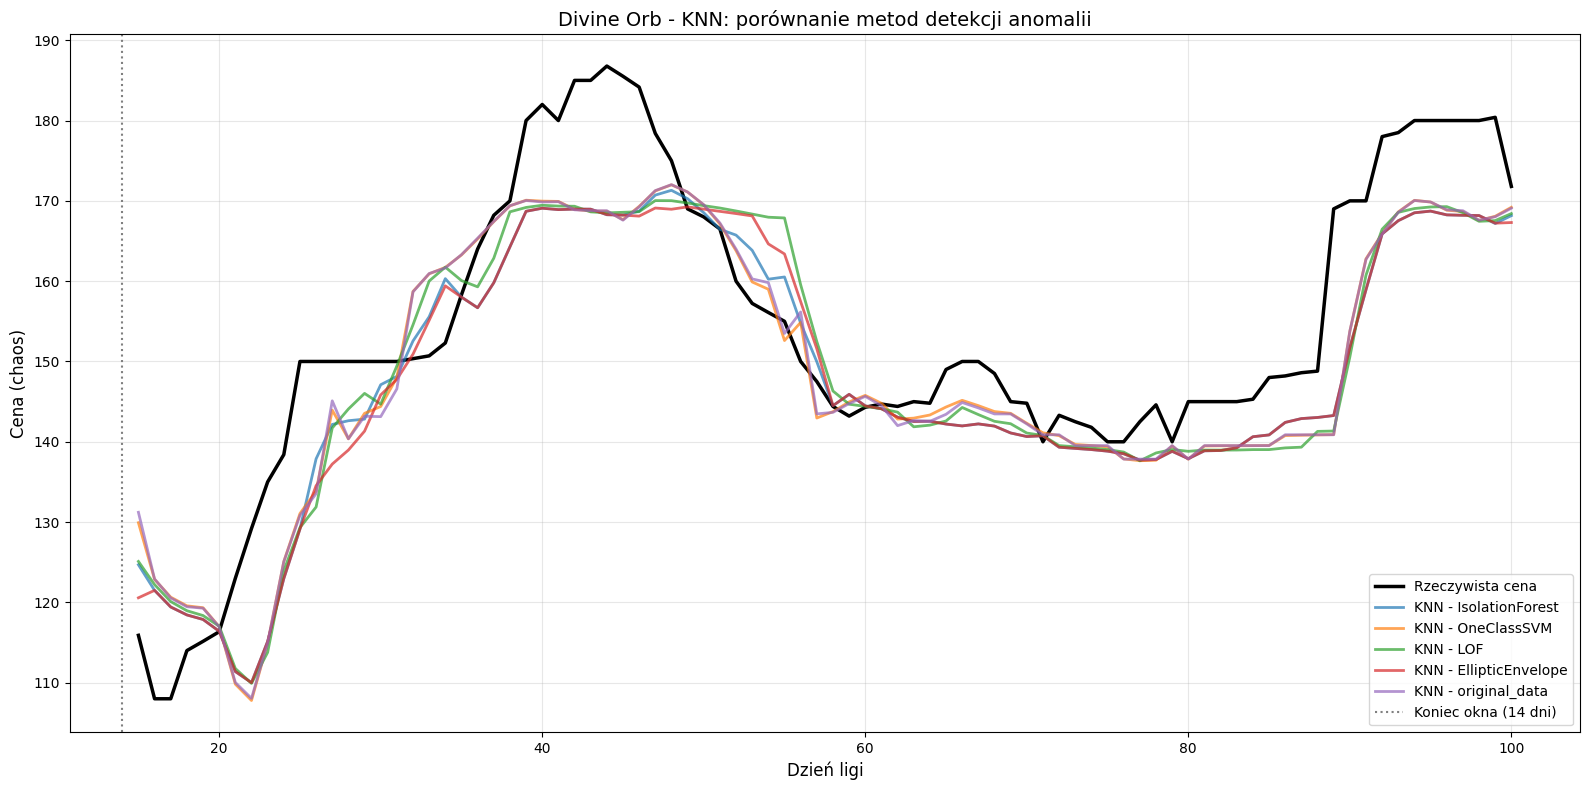

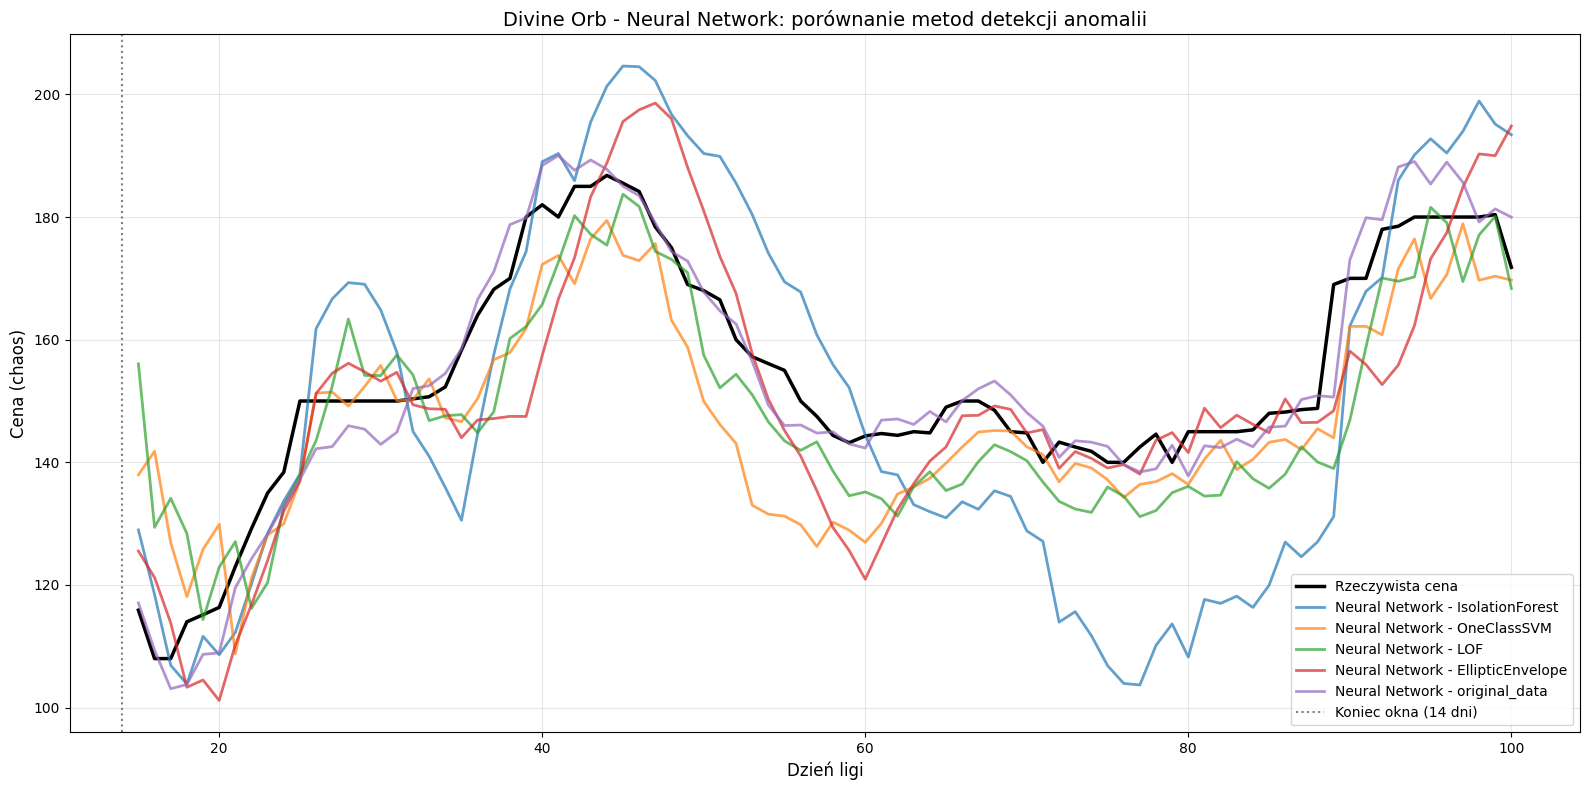

In [20]:
model_data = [
    ('Random Forest', preds_rf),
    ('SVR', preds_svr),
    ('KNN', preds_knn),
    ('Neural Network', preds_nn)
]

for model_name, pred_dict in model_data:
    plt.figure(figsize=(16, 8))
    plt.plot(days_preds, actuals_nn['IsolationForest'], label='Rzeczywista cena',
             color='black', lw=2.5)
    for method in pred_dict.keys():
        plt.plot(days_preds, pred_dict[method],
                 label=f'{model_name} - {method}', alpha=0.7, linewidth=2)
    plt.axvline(x=WINDOW, color='gray', linestyle=':',
                label=f'Koniec okna ({WINDOW} dni)')
    plt.title(
        f'{ITEM} - {model_name}: porównanie metod detekcji anomalii', fontsize=14)
    plt.xlabel('Dzień ligi', fontsize=12)
    plt.ylabel('Cena (chaos)', fontsize=12)
    plt.legend(loc='best')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()